# 04 · Comparing representation stabilization (CKA) with Neural Collapse

Combines the outputs of the previous notebooks to answer the central question of the thesis: **does the network's internal representation stop changing before, together with, or after the Neural Collapse geometry has formed?** It also locates the start of the Terminal Phase of Training (TPT). This is the CIFAR-100 version of the analysis.

**Inputs** (CSV files, found automatically in the folders listed in the config cell)
- `CKA_results.csv` – linear CKA of the `avgpool` features with the epoch-350 features (notebook 02)
- `NC_results.csv` – NC1–NC4 per checkpoint (notebook 03)
- `training_history.csv` – per-epoch training accuracy (notebook 01), used to locate the TPT

**Conventions**
- All stabilization epochs use the *strict* rule: the first checkpoint from which the criterion holds for every later checkpoint.
- NC metrics (lower = more collapsed): value ≤ 1.2 × final value; NC4: value ≤ final value + 0.01 (see notebook 03).
- CKA (higher = closer to the final representation): value ≥ 0.95 and ≥ 0.99.
- TPT start: first epoch whose *running* training accuracy (accumulated over the augmented batches of that epoch) reaches `TPT_ACC_THRESHOLD`. On CIFAR-10 the accuracy reaches exactly 100 % (threshold 100.0). On CIFAR-100 with augmentation it peaks at 99.99 % and never reaches 100 %, so a **relaxed** threshold of 99.9 % (≤ 0.1 % running training error) is used. This is a modified definition of the terminal phase; change `TPT_ACC_THRESHOLD` to test its sensitivity.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
import os

paths = [
    "/kaggle/input/notebooks/parinazghasemi/02-cfar100-compute-cka",
    "/kaggle/input/notebooks/parinazghasemi/03-cfar100-compute-neural-collapse",
    "/kaggle/input/notebooks/parinazghasemi/cfar100"
]

for path in paths:
    print("\nDirectory:", path)
    print("Exists:", os.path.exists(path))

    if os.path.exists(path):
        print("Files:", os.listdir(path))


Directory: /kaggle/input/notebooks/parinazghasemi/02-cfar100-compute-cka
Exists: True
Files: ['.virtual_documents', 'CKA_results.csv', '__notebook__.ipynb', '__output__.json', '__results__.html', '__results___files', 'cka_layerwise.csv', 'cka_layerwise_curves.png', 'cka_layerwise_heatmap.png', 'cka_stabilization_by_layer.png', 'cka_stabilization_summary.csv', 'custom.css']

Directory: /kaggle/input/notebooks/parinazghasemi/03-cfar100-compute-neural-collapse
Exists: True
Files: ['.virtual_documents', 'NC_results.csv', 'NC_stabilization_summary.csv', '__notebook__.ipynb', '__output__.json', '__results__.html', '__results___files', 'cifar100', 'custom.css', 'nc_metrics.png']

Directory: /kaggle/input/notebooks/parinazghasemi/cfar100
Exists: True
Files: ['.virtual_documents', '__notebook__.ipynb', '__output__.json', '__results__.html', 'checkpoints', 'custom.css', 'final_model.pth', 'training_history.csv']


## Load results

In [7]:
REQUIRED = ["CKA_results.csv", "NC_results.csv", "training_history.csv"]

cka_df = pd.read_csv("/kaggle/input/notebooks/parinazghasemi/02-cfar100-compute-cka/CKA_results.csv")
nc_df = pd.read_csv("/kaggle/input/notebooks/parinazghasemi/03-cfar100-compute-neural-collapse/NC_results.csv")
history = pd.read_csv("/kaggle/input/notebooks/parinazghasemi/cfar100/training_history.csv")
OUTPUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")
df = (
    nc_df.merge(cka_df[["epoch", "CKA"]], on="epoch", how="inner")
    .sort_values("epoch")
    .reset_index(drop=True)
)
print("Merged checkpoints:", len(df), "| epochs", df["epoch"].min(), "-", df["epoch"].max())

# First epoch whose running training accuracy reaches the threshold.
# 100.0 reproduces the CIFAR-10 definition; CIFAR-100 never reaches 100 %, hence the relaxed value.
TPT_ACC_THRESHOLD = 99.9
reached = history.loc[history["train_acc"] >= TPT_ACC_THRESHOLD, "epoch"]
assert len(reached) > 0, f"Training accuracy never reaches {TPT_ACC_THRESHOLD} % (max {history['train_acc'].max():.2f} %)"
TPT_EPOCH = int(reached.min())
print(f"TPT start (first epoch with running training accuracy >= {TPT_ACC_THRESHOLD} %): {TPT_EPOCH}")
print(f"Maximum running training accuracy: {history['train_acc'].max():.2f} %")

Merged checkpoints: 113 | epochs 1 - 350
TPT start (first epoch with running training accuracy >= 99.9 %): 281
Maximum running training accuracy: 99.99 %


## Stabilization epochs

In [8]:
def strict_below(epochs, values, threshold):
    epochs, values = np.asarray(epochs), np.asarray(values)
    for i in range(len(values)):
        if np.all(values[i:] <= threshold):
            return int(epochs[i])
    return None


def strict_above(epochs, values, threshold):
    epochs, values = np.asarray(epochs), np.asarray(values)
    for i in range(len(values)):
        if np.all(values[i:] >= threshold):
            return int(epochs[i])
    return None


epochs = df["epoch"].to_numpy()
records = []

for label, col in [("NC1", "NC1"), ("NC2", "NC2"), ("NC2 Angular", "NC2_angular"),
                   ("NC2 Norm", "NC2_norm"), ("NC3 Formal", "NC3_formal")]:
    final = df[col].iloc[-1]
    records.append({"Metric": label, "Criterion": "<= 1.2 x final", "Final Value": final,
                    "Threshold": 1.2 * final,
                    "Stabilization Epoch": strict_below(epochs, df[col], 1.2 * final)})

thr4 = df["NC4"].iloc[-1] + 0.01
records.append({"Metric": "NC4", "Criterion": "<= final + 0.01", "Final Value": df["NC4"].iloc[-1],
                "Threshold": thr4, "Stabilization Epoch": strict_below(epochs, df["NC4"], thr4)})

for t in (0.95, 0.99):
    records.append({"Metric": f"CKA {t}", "Criterion": f">= {t}", "Final Value": df["CKA"].iloc[-1],
                    "Threshold": t, "Stabilization Epoch": strict_above(epochs, df["CKA"], t)})

stab = pd.DataFrame(records)
stab["Relative to TPT"] = np.where(stab["Stabilization Epoch"] < TPT_EPOCH, "before TPT",
                          np.where(stab["Stabilization Epoch"] > TPT_EPOCH, "after TPT", "at TPT"))
stab.to_csv(OUTPUT_DIR / "stabilization_comparison.csv", index=False)
stab

,Metric,Criterion,Final Value,Threshold,Stabilization Epoch,Relative to TPT
0,NC1,<= 1.2 x final,0.113300,0.135960,314,after TPT
1,NC2,<= 1.2 x final,0.082800,0.099360,282,after TPT
2,NC2 Angular,<= 1.2 x final,0.072356,0.086827,278,before TPT
3,NC2 Norm,<= 1.2 x final,0.040256,0.048307,296,after TPT
4,NC3 Formal,<= 1.2 x final,0.186745,0.224094,280,before TPT
5,NC4,<= final + 0.01,0.031200,0.041200,286,after TPT
6,CKA 0.95,>= 0.95,1.000000,0.950000,286,after TPT
7,CKA 0.99,>= 0.99,1.000000,0.990000,314,after TPT


In [9]:
ranking = (
    stab[["Metric", "Stabilization Epoch"]]
    .sort_values("Stabilization Epoch")
    .reset_index(drop=True)
)
ranking.insert(0, "Order", np.arange(1, len(ranking) + 1))
ranking

,Order,Metric,Stabilization Epoch
0,1,NC2 Angular,278
1,2,NC3 Formal,280
2,3,NC2,282
3,4,NC4,286
4,5,CKA 0.95,286
5,6,NC2 Norm,296
6,7,NC1,314
7,8,CKA 0.99,314


## Sensitivity of the NC4 threshold
NC4 is a fraction of disagreeing test images, close to zero at the end of training, so a multiplicative threshold is not usable. The main analysis uses `final + 0.01`; the table below shows how the stabilization epoch changes if the tolerance is halved or doubled.

In [10]:
tolerances = [0.005, 0.01, 0.02]
final4 = df["NC4"].iloc[-1]

sens = pd.DataFrame({
    "tolerance above final": tolerances,
    "threshold": [final4 + t for t in tolerances],
    "stabilization epoch": [strict_below(epochs, df["NC4"], final4 + t) for t in tolerances],
})
sens["relative to TPT"] = np.where(sens["stabilization epoch"] < TPT_EPOCH, "before TPT",
                          np.where(sens["stabilization epoch"] > TPT_EPOCH, "after TPT", "at TPT"))
sens

,tolerance above final,threshold,stabilization epoch,relative to TPT
0,0.005,0.0362,304,after TPT
1,0.010,0.0412,286,after TPT
2,0.020,0.0512,278,before TPT


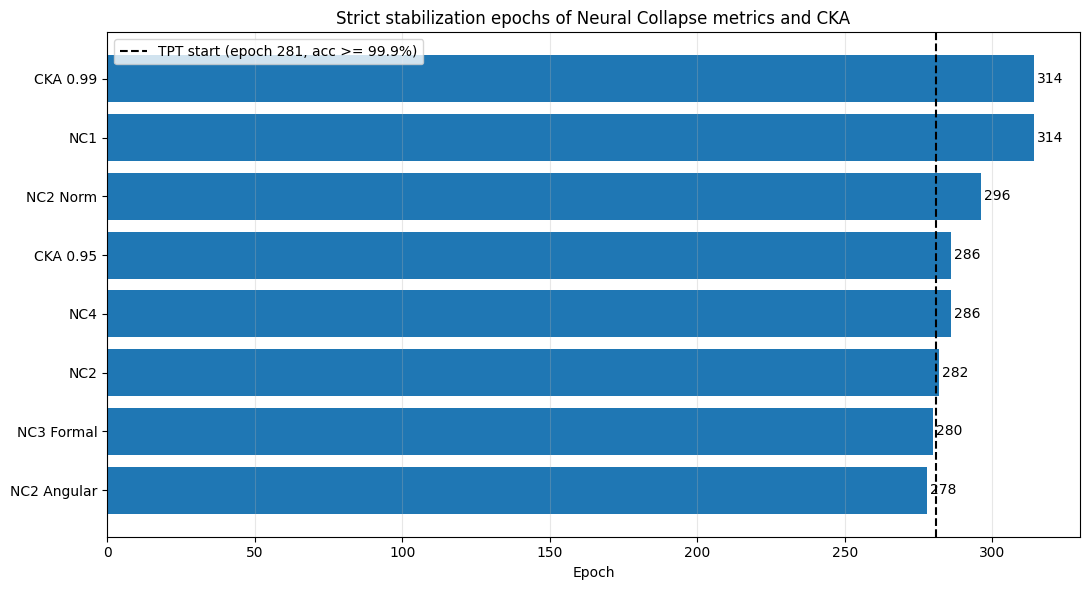

In [11]:
plot_df = stab.sort_values("Stabilization Epoch")

plt.figure(figsize=(11, 6))
plt.barh(plot_df["Metric"], plot_df["Stabilization Epoch"])
plt.axvline(TPT_EPOCH, color="k", linestyle="--", label=f"TPT start (epoch {TPT_EPOCH}, acc >= {TPT_ACC_THRESHOLD}%)")
for y, e in enumerate(plot_df["Stabilization Epoch"]):
    plt.text(e + 1, y, str(e), va="center")
plt.xlabel("Epoch")
plt.title("Strict stabilization epochs of Neural Collapse metrics and CKA")
plt.grid(axis="x", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "stabilization_epochs.png", dpi=200)
plt.show()

## Progress toward the final state
Each curve is rescaled so that 0 = value at epoch 1 and 1 = value at epoch 350, which makes metrics with different scales and directions comparable.

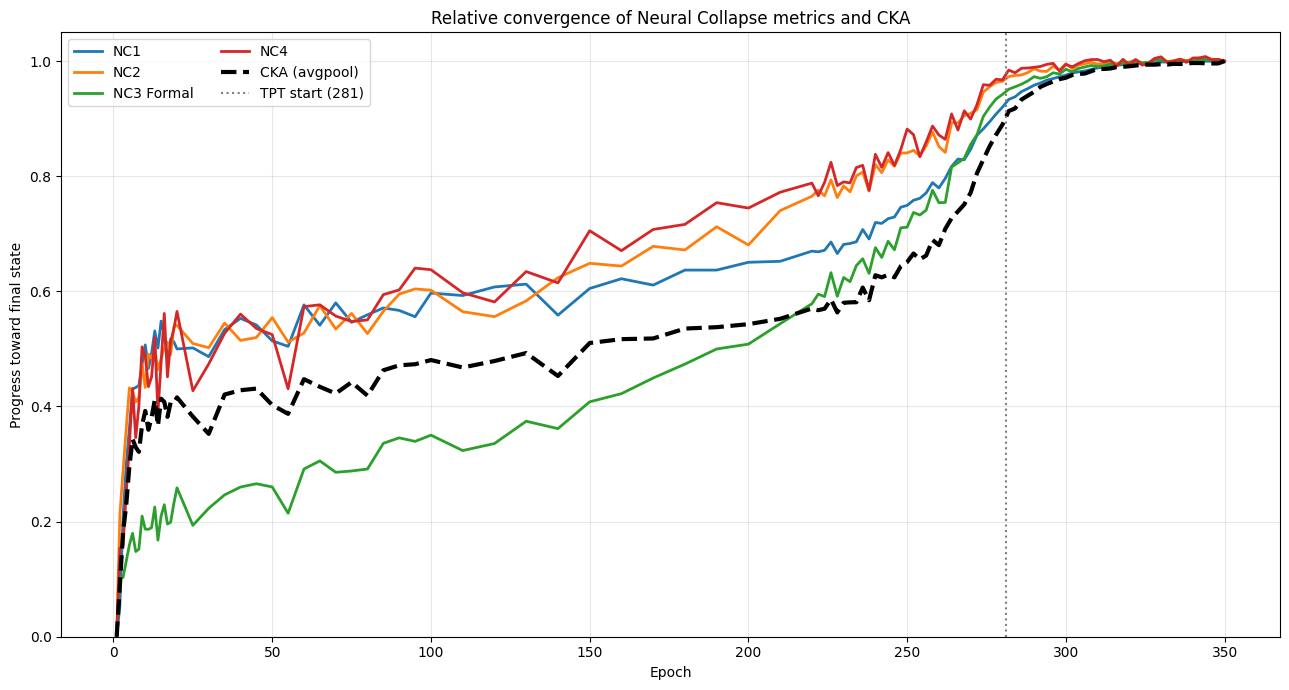

In [12]:
progress = pd.DataFrame({"epoch": df["epoch"]})
for label, col in [("NC1", "NC1"), ("NC2", "NC2"), ("NC3 Formal", "NC3_formal"), ("NC4", "NC4"), ("CKA", "CKA")]:
    first, last = df[col].iloc[0], df[col].iloc[-1]
    progress[label] = (first - df[col]) / (first - last)   # same formula works for both directions

plt.figure(figsize=(13, 7))
for label in ["NC1", "NC2", "NC3 Formal", "NC4"]:
    plt.plot(progress["epoch"], progress[label], linewidth=2, label=label)
plt.plot(progress["epoch"], progress["CKA"], linewidth=3, linestyle="--", color="k", label="CKA (avgpool)")
plt.axvline(TPT_EPOCH, color="gray", linestyle=":", label=f"TPT start ({TPT_EPOCH})")
plt.xlabel("Epoch")
plt.ylabel("Progress toward final state")
plt.title("Relative convergence of Neural Collapse metrics and CKA")
plt.ylim(0, 1.05)
plt.grid(True, alpha=0.3)
plt.legend(ncol=2)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "relative_convergence.png", dpi=200)
plt.show()

## Neural Collapse metrics around the start of the Terminal Phase of Training

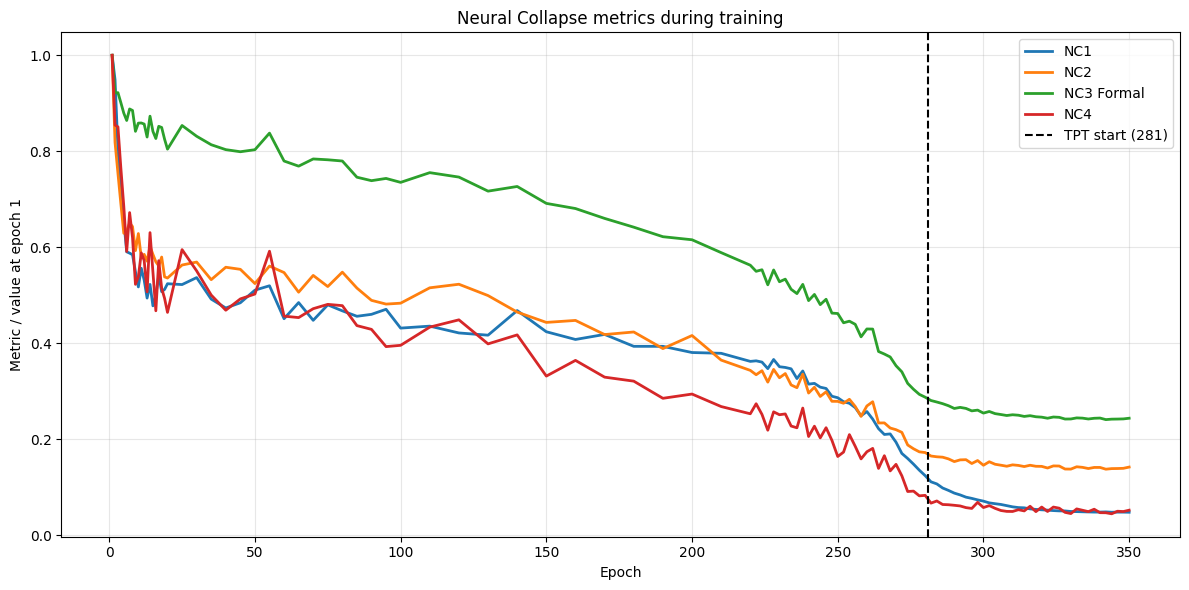

In [13]:
fig, ax = plt.subplots(figsize=(12, 6))
for label, col in [("NC1", "NC1"), ("NC2", "NC2"), ("NC3 Formal", "NC3_formal"), ("NC4", "NC4")]:
    ax.plot(df["epoch"], df[col] / df[col].iloc[0], linewidth=2, label=label)
ax.axvline(TPT_EPOCH, color="k", linestyle="--", label=f"TPT start ({TPT_EPOCH})")
ax.set_xlabel("Epoch")
ax.set_ylabel("Metric / value at epoch 1")
ax.set_title("Neural Collapse metrics during training")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "nc_metrics_with_tpt.png", dpi=200)
plt.show()